# E1 — Baselines and sanity checks (MNIST)

Vault: `Experiments/MNIST/E1 Baselines and sanity checks`. Goal: know what **linear** achieves, and make sure the pipeline is correct before comparing anything.

1. PCA spectrum of the full training set
2. Per-class PCA (one manifold per digit?)
3. Sanity checks of the shared code
4. Reference values: $k$-NN accuracy and silhouette in pixel space
5. PCA baseline: $R_{NX}$ curves for $q = 2$ and $q = 10$

Each section ends with the numbers to copy into `MNIST — Results log`.

In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make the nldr package importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nldr import config, data, metrics, methods, plotting

config.RESULTS_DIR.mkdir(exist_ok=True)
config.FIGURES_DIR.mkdir(exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
X, y = data.load_mnist()
X_pool, y_pool = X[:60000], y[:60000]
splits = data.make_splits()
results = {}          # everything worth logging ends up here

/opt/anaconda3/envs/nldr/lib/python3.12/site-packages/sklearn/datasets/_openml.py:95: RuntimeWarning: Invalid cache, redownloading file to /Users/eileenhappy/Desktop/MINIST/data/openml/openml.org/data/v1/download/52667/mnist_784.arff.gz
  warn(


fast ARFF reader failed (TypeError); using the slower pure-Python reader, this takes a minute or two...


## 1. PCA spectrum (60,000 training images)

Eigenvalues $\lambda_a$ of $\hat\Sigma$ and the cumulative explained variance $\sum_{a\le q}\lambda_a / \operatorname{tr}\hat\Sigma$. Look for eigengaps and read off the number of components for 80 / 90 / 95 %.

components needed: {'80%': 44, '90%': 87, '95%': 154, '99%': 331}


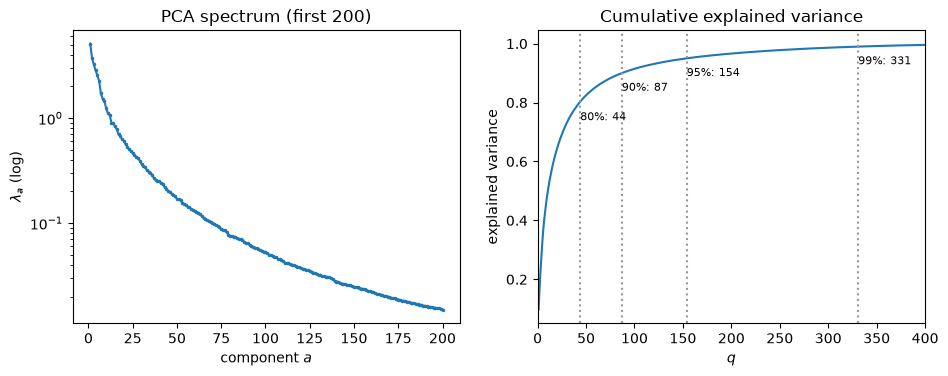

In [5]:
from sklearn.decomposition import PCA

pca_full = PCA(svd_solver="full").fit(X_pool)
lam = pca_full.explained_variance_
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_for = {p: int(np.searchsorted(cum, p) + 1) for p in (0.8, 0.9, 0.95, 0.99)}
results["pca_components_for"] = n_for
print("components needed:", {f"{int(100*p)}%": q for p, q in n_for.items()})

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogy(np.arange(1, 201), lam[:200], ".-", ms=3)
ax[0].set(xlabel="component $a$", ylabel=r"$\lambda_a$ (log)", title="PCA spectrum (first 200)")
ax[1].plot(np.arange(1, lam.size + 1), cum)
for p, q in n_for.items():
    ax[1].axvline(q, ls=":", c="0.6"); ax[1].text(q, p - 0.06, f"{int(100*p)}%: {q}", fontsize=8)
ax[1].set(xlabel="$q$", ylabel="explained variance", xlim=(0, 400), title="Cumulative explained variance")
plotting.save(fig, "E1_pca_spectrum"); plt.show()

## 2. Per-class PCA

If each digit lies near its own lower-dimensional manifold, a single class should need **fewer** components than all classes together.

In [6]:
rows = []
for digit in range(10):
    cum_c = np.cumsum(PCA(svd_solver="full").fit(X_pool[y_pool == digit]).explained_variance_ratio_)
    rows.append({"digit": digit, "q_90%": int(np.searchsorted(cum_c, 0.9) + 1),
                 "q_95%": int(np.searchsorted(cum_c, 0.95) + 1)})
per_class = pd.DataFrame(rows).set_index("digit")
per_class.loc["all"] = [n_for[0.9], n_for[0.95]]
results["per_class_q90"] = per_class["q_90%"].to_dict()
per_class.to_csv(config.RESULTS_DIR / "E1_per_class_pca.csv")
per_class.T

digit,0,1,2,3,4,5,6,7,8,9,all
q_90%,62,36,81,80,76,75,62,66,82,62,87
q_95%,116,71,142,138,135,130,113,121,137,111,154


## 3. Sanity checks of the shared code

First the unit tests (toy example of the vault, equivalences between methods), then the same checks on real MNIST data from split 0.

In [7]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "-q", str(Path.cwd().parent / "tests")],
                     capture_output=True, text=True, cwd=Path.cwd().parent).stdout[-600:])

a3/envs/nldr/lib/python3.12/site-packages/scipy/sparse/_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
    self._set_intXint(row, col, x.flat[0])

tests/test_metrics.py::test_umap_runs
  /opt/anaconda3/envs/nldr/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
    warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
17 passed, 5 warnings in 8.52s



In [8]:
s = splits[0]
Xtr, Xte = X[s.tr], X[s.te]
rho = metrics.rank_matrix(Xtr)          # input ranks: reused below

def same_up_to_sign(A, B, tol=1e-6):
    return np.allclose(A * np.sign(np.sum(A * B, axis=0)), B, atol=tol)

pca10 = methods.fit("pca", Xtr, 10)
checks = {
    "linear kernel PCA = PCA": same_up_to_sign(methods.fit("kpca", Xtr, 10, {"kernel": "linear"}).Y, pca10.Y),
    "classical MDS = PCA": same_up_to_sign(methods.fit("mds", Xtr, 10).Y, pca10.Y),
    "out-of-sample PCA reproduces training embedding": np.allclose(pca10.transform(Xtr), pca10.Y),
    "R_NX(Y = X) = 1": np.allclose(metrics.rnx_curve(rho, rho), 1.0),
}
Y_rand = np.random.default_rng(0).normal(size=(len(s.tr), 2))
J_rand = metrics.auc_log(metrics.rnx_curve(rho, metrics.rank_matrix(Y_rand)))
checks["random embedding: |J| < 0.02"] = abs(J_rand) < 0.02
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
print(f"J of a random embedding: {J_rand:+.4f}")

PASS linear kernel PCA = PCA
PASS classical MDS = PCA
PASS out-of-sample PCA reproduces training embedding
PASS R_NX(Y = X) = 1
PASS random embedding: |J| < 0.02
J of a random embedding: -0.0008


## 4. Reference values in pixel space

The ceiling for embedded $k$-NN accuracy, and how separated the classes really are before any reduction. Mean ± s.d. over the $S$ splits.

In [9]:
from sklearn.metrics import silhouette_score

rows = []
for s in splits:
    rows.append({
        "split": s.seed,
        "knn_acc_oos": metrics.knn_accuracy_oos(X[s.tr], y[s.tr], X[s.te], y[s.te], k=config.KNN_CLASSIFIER_K),
        "knn_acc_cv": metrics.knn_accuracy(X[s.te], y[s.te], k=config.KNN_CLASSIFIER_K),
        "silhouette": silhouette_score(X[s.te], y[s.te]),
    })
ref = pd.DataFrame(rows).set_index("split")
ref.to_csv(config.RESULTS_DIR / "E1_reference_pixel_space.csv")
results["reference_pixel_space"] = ref.agg(["mean", "std"]).round(4).to_dict()
ref.agg(["mean", "std"]).round(4)

,knn_acc_oos,knn_acc_cv,silhouette
mean,0.8996,0.8981,0.0411
std,0.0077,0.0050,0.0021


## 5. PCA baseline curves

The benchmark every nonlinear method must beat: $R_{NX}(K)$ of PCA on $X_{\mathrm{te}}$ of split 0, for $q = 2$ (figures) and $q = 10$ (tables).

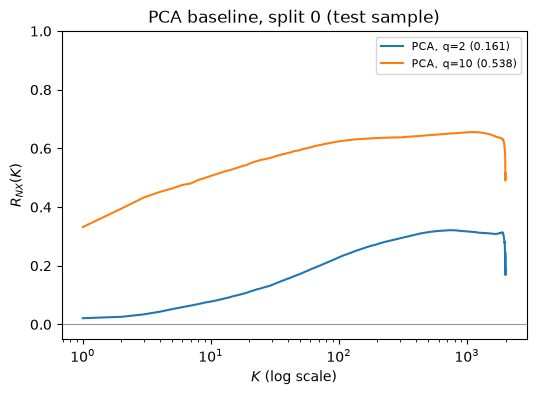

,J,T5,C5,T10,C10,T50,C50,spearman,centroid_corr,knn_acc,silhouette,ari,nmi
q,,,,,,,,,,,,,
2,0.1614,0.7345,0.9167,0.7336,0.9046,0.7367,0.8692,0.4902,0.8514,0.411,0.0146,0.2339,0.3659
10,0.5384,0.9871,0.9952,0.9838,0.9933,0.9702,0.9846,0.8458,0.9955,0.871,0.0876,0.3029,0.4474


In [10]:
s = splits[0]
Xte, yte = X[s.te], y[s.te]
rho_te = metrics.rank_matrix(Xte)
curves, rows = {}, []
for q in (config.Q_FIGURES, config.Q_TABLES):
    Y = methods.fit("pca", Xte, q).Y
    res = metrics.evaluate(Xte, Y, yte, Ks=config.K_REPORT, rho=rho_te)
    curves[f"PCA, q={q}"] = (res.pop("rnx"), res["J"])
    rows.append({"q": q, **{k: round(v, 4) for k, v in res.items()}})
pca_baseline = pd.DataFrame(rows).set_index("q")
pca_baseline.to_csv(config.RESULTS_DIR / "E1_pca_baseline_split0.csv")
results["pca_baseline_split0"] = pca_baseline.to_dict(orient="index")

fig, ax = plt.subplots(figsize=(6, 4))
plotting.rnx_curves(curves, ax=ax, title="PCA baseline, split 0 (test sample)")
plotting.save(fig, "E1_pca_baseline_rnx"); plt.show()
pca_baseline

## 6. Summary for the results log

In [11]:
import json, datetime
print(f"### {datetime.date.today()} — E1 — baselines and sanity checks")
print(f"- Data: n = {config.N_PER_SPLIT} per split, S = {config.N_REPEATS}, pixels in [0, 1]")
print("- Checks:", "all passed" if all(checks.values()) else "FAILURES: " + str([k for k, v in checks.items() if not v]))
print(json.dumps(results, indent=1, default=float))

### 2026-11-23 — E1 — baselines and sanity checks
- Data: n = 2000 per split, S = 5, pixels in [0, 1]
- Checks: all passed
{
 "pca_components_for": {
  "0.8": 44,
  "0.9": 87,
  "0.95": 154,
  "0.99": 331
 },
 "per_class_q90": {
  "0": 62,
  "1": 36,
  "2": 81,
  "3": 80,
  "4": 76,
  "5": 75,
  "6": 62,
  "7": 66,
  "8": 82,
  "9": 62,
  "all": 87
 },
 "reference_pixel_space": {
  "knn_acc_oos": {
   "mean": 0.8996,
   "std": 0.0077
  },
  "knn_acc_cv": {
   "mean": 0.8981,
   "std": 0.005
  },
  "silhouette": {
   "mean": 0.0411,
   "std": 0.0021
  }
 },
 "pca_baseline_split0": {
  "2": {
   "J": 0.1614,
   "T5": 0.7345,
   "C5": 0.9167,
   "T10": 0.7336,
   "C10": 0.9046,
   "T50": 0.7367,
   "C50": 0.8692,
   "spearman": 0.4902,
   "centroid_corr": 0.8514,
   "knn_acc": 0.411,
   "silhouette": 0.0146,
   "ari": 0.2339,
   "nmi": 0.3659
  },
  "10": {
   "J": 0.5384,
   "T5": 0.9871,
   "C5": 0.9952,
   "T10": 0.9838,
   "C10": 0.9933,
   "T50": 0.9702,
   "C50": 0.9846,
   "spearma